## 0. Configuration

In [2]:
import os, json, hashlib, random, time, copy
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, classification_report, confusion_matrix, roc_auc_score)

# ---------------- paths ----------------
# Folder that contains metadata.csv and the imgs_part_* folders (searched recursively).
# Kaggle: add the dataset "mahdavi1202/skin-cancer" to the notebook -> it appears under /kaggle/input/
DATA_ROOT   = Path("/kaggle/input")
# Team split produced by data_preprocessing.ipynb (Dataset/processed/splits.csv).
# If the file is not found, the split is regenerated with the identical code and seed.
SPLITS_PATH = next(Path("/kaggle/input").rglob("splits*.csv"), Path("splits.csv"))
OUT_DIR     = Path("cnn_outputs_v3"); OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR   = OUT_DIR / "cache_256"

# ---------------- training ----------------
SEED            = 42
IMG_SIZE        = 224
CACHE_SIZE      = 256
BATCH_SIZE      = 32
NUM_WORKERS     = 4
VAL_FOLD        = 0      # inner fold of the training set used for validation / early stopping
EPOCHS_HEAD     = 8      # stage 1: backbone frozen, head only
EPOCHS_FINETUNE = 30     # stage 2: last blocks unfrozen (cosine schedule length)
PATIENCE        = 8
N_CV_FOLDS      = 5      # set to 1 for a quick single-fold run
USE_TTA         = True     # early stopping on validation macro-F1
PRETRAINED      = True
DROP_CONFLICTING_DUPLICATES = True

# Same label encoding as data_preprocessing.ipynb
LABEL_MAP = {"NEV": 0, "ACK": 1, "SEK": 2, "BCC": 3, "SCC": 4, "MEL": 5}
CLASSES   = list(LABEL_MAP)                       # index order
MALIGNANT = ["BCC", "SCC", "MEL"]
MAL_IDX   = [LABEL_MAP[c] for c in MALIGNANT]

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu130


## 1. Load metadata and the team's patient-level split
Every experiment (metadata-only, image-only, fusion) must be evaluated on the **same test patients**,
otherwise the comparison between modalities is not meaningful.

In [3]:
meta_csv = next(DATA_ROOT.rglob("metadata.csv"))
df = pd.read_csv(meta_csv)
img_paths = {p.name: p for p in DATA_ROOT.rglob("*.png")}
df["path"]  = df["img_id"].map(img_paths)
assert df["path"].notna().all(), "some images listed in metadata.csv were not found"
df["label"] = df["diagnostic"].map(LABEL_MAP)
print("Images:", len(df), "| patients:", df.patient_id.nunique())

if SPLITS_PATH.exists():
    splits = pd.read_csv(SPLITS_PATH)
    print("Loaded team split from", SPLITS_PATH)
else:
    # Identical to data_preprocessing.ipynb: StratifiedGroupKFold on patient_id, seed 42
    print("splits.csv not found -> regenerating with the same code/seed as data_preprocessing.ipynb")
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr_i, te_i = next(outer.split(df, df["diagnostic"], df["patient_id"]))
    tr, te = df.iloc[tr_i].copy(), df.iloc[te_i].copy()
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr["fold"] = -1
    for k, (_, v) in enumerate(inner.split(tr, tr["diagnostic"], tr["patient_id"])):
        tr.iloc[v, tr.columns.get_loc("fold")] = k
    splits = pd.concat([tr[["patient_id", "img_id", "fold"]].assign(split="train"),
                        te[["patient_id", "img_id"]].assign(split="test", fold=-1)])
    splits.to_csv(OUT_DIR / "splits_regenerated.csv", index=False)

df = df.merge(splits[["img_id", "split", "fold"]], on="img_id", how="left", validate="one_to_one")
assert df["split"].notna().all()
assert not set(df[df.split == "train"].patient_id) & set(df[df.split == "test"].patient_id), "patient leakage!"

df["subset"] = np.where(df.split == "test", "test", np.where(df.fold == VAL_FOLD, "val", "train"))
print(df.groupby(["subset", "diagnostic"]).size().unstack(0)[["train", "val", "test"]])
print("Expected from the team split: 1838 train+val rows, 460 test rows ->",
      (df.split == "train").sum(), (df.split == "test").sum())

Images: 2298 | patients: 1373
splits.csv not found -> regenerating with the same code/seed as data_preprocessing.ipynb
subset      train  val  test
diagnostic                  
ACK           483  103   144
BCC           530  142   173
MEL            34    5    13
NEV           165   34    45
SCC           129   26    37
SEK           148   39    48
Expected from the team split: 1838 train+val rows, 460 test rows -> 1838 460


## 2. Duplicate images
The EDA found 15 pairs of byte-identical images; 12 pairs carry **different** diagnoses.
Showing the network the same picture with two labels only adds noise, so in the **training/validation** data
conflicting pairs are removed and same-label pairs keep one copy. The **test set is left unchanged**
so it stays identical to the one used by the metadata models.

In [4]:
def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(8) as ex:
    df["md5"] = list(ex.map(md5, df["path"]))

dups = df[df.md5.duplicated(keep=False)]
n_labels = dups.groupby("md5")["diagnostic"].nunique()
conflict_hashes = set(n_labels[n_labels > 1].index)
print(f"Duplicate groups: {dups.md5.nunique()} | conflicting labels: {len(conflict_hashes)}")

df["use_for_training"] = True
if DROP_CONFLICTING_DUPLICATES:
    trval = df.subset != "test"
    df.loc[trval & df.md5.isin(conflict_hashes), "use_for_training"] = False
    same_dup_extra = trval & ~df.md5.isin(conflict_hashes) & df.duplicated("md5", keep="first")
    df.loc[same_dup_extra, "use_for_training"] = False
print("Rows removed from train/val:", (~df.use_for_training).sum())
print("Duplicates left in test (shared with other experiments):", df[df.subset == "test"].md5.duplicated(keep=False).sum())

Duplicate groups: 15 | conflicting labels: 12
Rows removed from train/val: 13
Duplicates left in test (shared with other experiments): 14


## 3. Resize once and cache (images up to ~23 MB each would make every epoch very slow)

In [5]:
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def cache_one(args):
    src, img_id = args
    dst = CACHE_DIR / (Path(img_id).stem + ".jpg")
    if not dst.exists():
        Image.open(src).convert("RGB").resize((CACHE_SIZE, CACHE_SIZE), Image.BICUBIC).save(dst, quality=95)
    return str(dst)

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    df["cached"] = list(ex.map(cache_one, zip(df["path"], df["img_id"])))
print(f"Cached {len(df)} images at {CACHE_SIZE}px in {time.time() - t0:.0f}s")

Cached 2298 images at 256px in 49s


## 4. Datasets, augmentation and class weights
Augmentation (training only): random crop/zoom, horizontal + vertical flips, rotation (lesions have no natural orientation)
and colour jitter (smartphone lighting varies). Normalisation uses ImageNet statistics.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class LesionDS(Dataset):
    def __init__(self, frame, tf):
        self.paths, self.labels, self.tf = frame["cached"].tolist(), frame["label"].tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

train_df = df[(df.subset == "train") & df.use_for_training]
val_df   = df[(df.subset == "val") & df.use_for_training]
test_df  = df[df.subset == "test"]

def loader(frame, tf, shuffle):
    return DataLoader(LesionDS(frame, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=USE_AMP)
train_dl, val_dl, test_dl = loader(train_df, train_tf, True), loader(val_df, eval_tf, False), loader(test_df, eval_tf, False)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

# 'balanced' weights: n_samples / (n_classes * n_class) -> rare classes (MEL) count more in the loss
cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_df["label"])
print("Class weights:", dict(zip(CLASSES, cw.round(2))))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=device))

train 1479 | val 346 | test 460
Class weights: {'NEV': np.float64(1.5), 'ACK': np.float64(0.51), 'SEK': np.float64(1.68), 'BCC': np.float64(0.47), 'SCC': np.float64(1.91), 'MEL': np.float64(7.25)}


## 5. Model, training loop and test-time augmentation
* **Stage 1:** backbone frozen, the new head (Dropout → Dense 256 → ReLU → Dropout → Dense 6) is trained for `EPOCHS_HEAD` epochs.
* **Stage 2:** `features[5:]` (the last EfficientNet stages) + head are unfrozen with smaller learning rates and a cosine
  schedule; **BatchNorm layers stay frozen** (running statistics and parameters).
* During CV, stage 2 stops early on validation macro-F1 and the best epoch is recorded. The final model is trained for the
  median best epoch, on all training data, with the same schedule.

In [7]:
def build_model():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if PRETRAINED else None)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 256), nn.ReLU(inplace=True),
                                 nn.Dropout(0.3), nn.Linear(256, len(CLASSES)))
    return m.to(device)

def freeze_bn(model):
    for mod in model.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()
            for p in mod.parameters(): p.requires_grad = False

@torch.no_grad()
def predict(model, dl, tta=False):
    model.eval(); probs, ys = [], []
    for x, y in dl:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=USE_AMP):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, [3])).float().softmax(1)
                       + model(torch.flip(x, [2])).float().softmax(1)) / 3
        probs.append(p.cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def run_epochs(model, groups, criterion, train_dl, schedule_len, n_epochs, val_dl=None, patience=None, tag=""):
    """Train n_epochs (cosine over schedule_len). With val_dl: early stopping on macro-F1, restore best."""
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=schedule_len)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    hist, best_f1, best_ep, best_state, wait = [], -1, 0, None, 0
    for ep in range(1, n_epochs + 1):
        model.train(); freeze_bn(model); t0, tot, n = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        row = dict(epoch=ep, train_loss=tot / n)
        if val_dl is not None:
            p, yv = predict(model, val_dl)
            row.update(val_macro_f1=f1_score(yv, p.argmax(1), average="macro"), val_acc=accuracy_score(yv, p.argmax(1)))
            if row["val_macro_f1"] > best_f1:
                best_f1, best_ep, best_state, wait = row["val_macro_f1"], ep, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
        hist.append(row)
        print(f"[{tag}] ep {ep:02d} | loss {row['train_loss']:.3f}"
              + (f" | val_acc {row['val_acc']:.3f} | val_macroF1 {row['val_macro_f1']:.3f}" if val_dl else "")
              + f" | {time.time()-t0:.0f}s")
        if val_dl is not None and patience and wait >= patience:
            print(f"[{tag}] early stopping"); break
    if best_state is not None:
        model.load_state_dict(best_state)
    return pd.DataFrame(hist), best_ep, best_f1

def two_stage(train_frame, val_frame=None, finetune_epochs=EPOCHS_FINETUNE, tag=""):
    seed_everything()
    cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_frame["label"])
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=device))
    tr_dl = loader(train_frame, train_tf, True)
    va_dl = loader(val_frame, eval_tf, False) if val_frame is not None else None
    model = build_model()
    # stage 1: head only
    for p in model.parameters(): p.requires_grad = False
    for p in model.classifier.parameters(): p.requires_grad = True
    run_epochs(model, [{"params": model.classifier.parameters(), "lr": 1e-3}], criterion, tr_dl,
               EPOCHS_HEAD, EPOCHS_HEAD, tag=f"{tag} head")
    # stage 2: unfreeze last stages (BatchNorm stays frozen)
    for p in model.features[5:].parameters(): p.requires_grad = True
    freeze_bn(model)
    groups = [{"params": [p for p in model.features[5].parameters() if p.requires_grad], "lr": 3e-5},
              {"params": [p for p in model.features[6:].parameters() if p.requires_grad], "lr": 1e-4},
              {"params": model.classifier.parameters(), "lr": 3e-4}]
    hist, best_ep, best_f1 = run_epochs(model, groups, criterion, tr_dl, EPOCHS_FINETUNE, finetune_epochs,
                                        val_dl=va_dl, patience=PATIENCE, tag=f"{tag} fine-tune")
    return model, hist, best_ep, best_f1

## 6. 5-fold patient-level cross-validation (training set only)
The `fold` column of the team split already assigns every training patient to one of 5 folds. Each fold is used once
as validation; the other four train a fresh model. The test set is not touched here.

In [8]:
trainval = df[(df.split == "train") & df.use_for_training].copy()
folds = sorted(trainval.fold.unique())[:N_CV_FOLDS]
cv_rows, cv_hists = [], {}
oof = pd.DataFrame(np.nan, index=trainval.index, columns=[f"p_{c}" for c in CLASSES])

t_cv = time.time()
for k in folds:
    tr, va = trainval[trainval.fold != k], trainval[trainval.fold == k]
    assert not set(tr.patient_id) & set(va.patient_id)
    model, hist, best_ep, best_f1 = two_stage(tr, va, tag=f"fold {k}")
    p, yv = predict(model, loader(va, eval_tf, False), tta=USE_TTA)
    oof.loc[va.index] = p
    cv_rows.append(dict(fold=k, best_epoch=best_ep, n_val=len(va),
                        accuracy=accuracy_score(yv, p.argmax(1)),
                        balanced_accuracy=balanced_accuracy_score(yv, p.argmax(1)),
                        macro_f1=f1_score(yv, p.argmax(1), average="macro")))
    cv_hists[k] = hist
    print(f"==> fold {k}: macro-F1 {cv_rows[-1]['macro_f1']:.3f} (best fine-tune epoch {best_ep})\n")
    del model; torch.cuda.empty_cache()

cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv(OUT_DIR / "cv_results.csv", index=False)
FINAL_EPOCHS = int(np.median(cv_df.best_epoch))
print(f"CV finished in {(time.time()-t_cv)/60:.0f} min")
print(cv_df.round(3).to_string(index=False))
print(f"\nCV macro-F1: {cv_df.macro_f1.mean():.3f} ± {cv_df.macro_f1.std():.3f} | "
      f"balanced acc: {cv_df.balanced_accuracy.mean():.3f} ± {cv_df.balanced_accuracy.std():.3f}")
print("Final model fine-tune epochs (median best epoch):", FINAL_EPOCHS)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 146MB/s]


[fold 0 head] ep 01 | loss 1.533 | 18s
[fold 0 head] ep 02 | loss 1.162 | 6s
[fold 0 head] ep 03 | loss 1.095 | 6s
[fold 0 head] ep 04 | loss 0.994 | 6s
[fold 0 head] ep 05 | loss 0.948 | 6s
[fold 0 head] ep 06 | loss 0.905 | 6s
[fold 0 head] ep 07 | loss 0.855 | 6s
[fold 0 head] ep 08 | loss 0.844 | 6s
[fold 0 fine-tune] ep 01 | loss 0.949 | val_acc 0.448 | val_macroF1 0.413 | 24s
[fold 0 fine-tune] ep 02 | loss 0.848 | val_acc 0.552 | val_macroF1 0.489 | 7s
[fold 0 fine-tune] ep 03 | loss 0.705 | val_acc 0.613 | val_macroF1 0.537 | 7s
[fold 0 fine-tune] ep 04 | loss 0.706 | val_acc 0.598 | val_macroF1 0.580 | 7s
[fold 0 fine-tune] ep 05 | loss 0.603 | val_acc 0.592 | val_macroF1 0.595 | 7s
[fold 0 fine-tune] ep 06 | loss 0.488 | val_acc 0.639 | val_macroF1 0.608 | 7s
[fold 0 fine-tune] ep 07 | loss 0.426 | val_acc 0.679 | val_macroF1 0.618 | 7s
[fold 0 fine-tune] ep 08 | loss 0.420 | val_acc 0.685 | val_macroF1 0.612 | 7s
[fold 0 fine-tune] ep 09 | loss 0.425 | val_acc 0.639 | val_ma

### Cross-validation curves

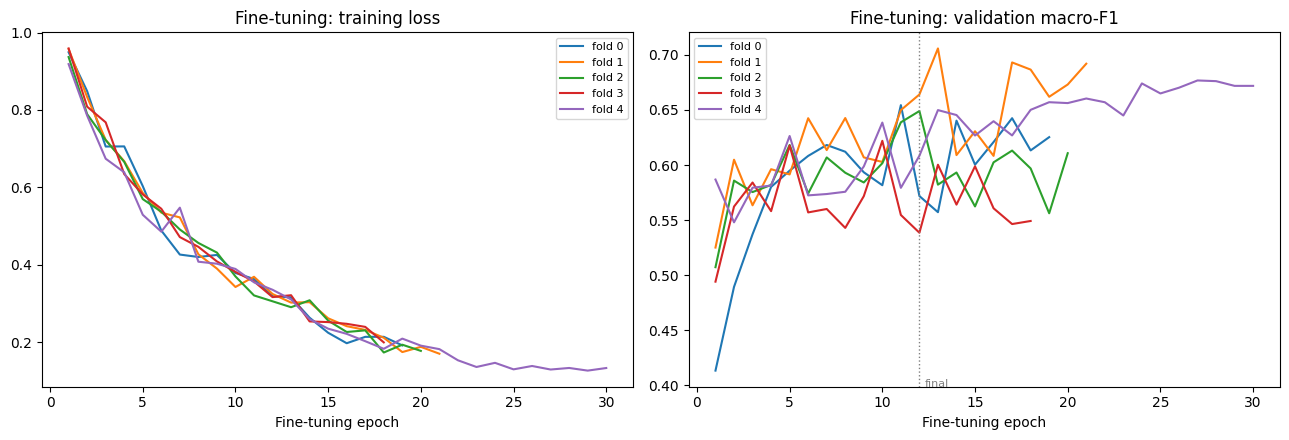

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, h in cv_hists.items():
    axes[0].plot(h.epoch, h.train_loss, label=f"fold {k}")
    axes[1].plot(h.epoch, h.val_macro_f1, label=f"fold {k}")
axes[1].axvline(FINAL_EPOCHS, color="grey", ls=":", lw=1); axes[1].text(FINAL_EPOCHS + 0.3, axes[1].get_ylim()[0], "final", color="grey", fontsize=8)
for ax, t in zip(axes, ["Fine-tuning: training loss", "Fine-tuning: validation macro-F1"]):
    ax.set_title(t); ax.set_xlabel("Fine-tuning epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "cv_curves.png", dpi=200); plt.show()

## 7. Final model: retrain on all 1,838 training images
Same recipe, no validation split, fine-tuned for the CV-selected number of epochs.

In [10]:
final_model, final_hist, _, _ = two_stage(trainval, None, finetune_epochs=FINAL_EPOCHS, tag="final")
torch.save(final_model.state_dict(), OUT_DIR / "effnet_b0_final.pt")

[final head] ep 01 | loss 1.484 | 9s
[final head] ep 02 | loss 1.152 | 7s
[final head] ep 03 | loss 1.093 | 7s
[final head] ep 04 | loss 1.019 | 7s
[final head] ep 05 | loss 0.955 | 7s
[final head] ep 06 | loss 0.918 | 7s
[final head] ep 07 | loss 0.864 | 7s
[final head] ep 08 | loss 0.846 | 7s
[final fine-tune] ep 01 | loss 0.955 | 12s
[final fine-tune] ep 02 | loss 0.831 | 8s
[final fine-tune] ep 03 | loss 0.710 | 8s
[final fine-tune] ep 04 | loss 0.635 | 7s
[final fine-tune] ep 05 | loss 0.570 | 7s
[final fine-tune] ep 06 | loss 0.562 | 7s
[final fine-tune] ep 07 | loss 0.496 | 8s
[final fine-tune] ep 08 | loss 0.459 | 8s
[final fine-tune] ep 09 | loss 0.421 | 8s
[final fine-tune] ep 10 | loss 0.349 | 8s
[final fine-tune] ep 11 | loss 0.380 | 8s
[final fine-tune] ep 12 | loss 0.404 | 8s


## 8. Test-set evaluation (460 images, same patients as the metadata models) — used once


===== EfficientNet-B0 (no TTA) =====
              precision    recall  f1-score   support

         NEV      0.816     0.689     0.747        45
         ACK      0.755     0.729     0.742       144
         SEK      0.574     0.729     0.642        48
         BCC      0.777     0.786     0.782       173
         SCC      0.286     0.270     0.278        37
         MEL      0.583     0.538     0.560        13

    accuracy                          0.704       460
   macro avg      0.632     0.624     0.625       460
weighted avg      0.708     0.704     0.705       460


===== EfficientNet-B0 + TTA =====
              precision    recall  f1-score   support

         NEV      0.821     0.711     0.762        45
         ACK      0.765     0.722     0.743       144
         SEK      0.633     0.792     0.704        48
         BCC      0.750     0.780     0.765       173
         SCC      0.294     0.270     0.282        37
         MEL      0.636     0.538     0.583        13

    

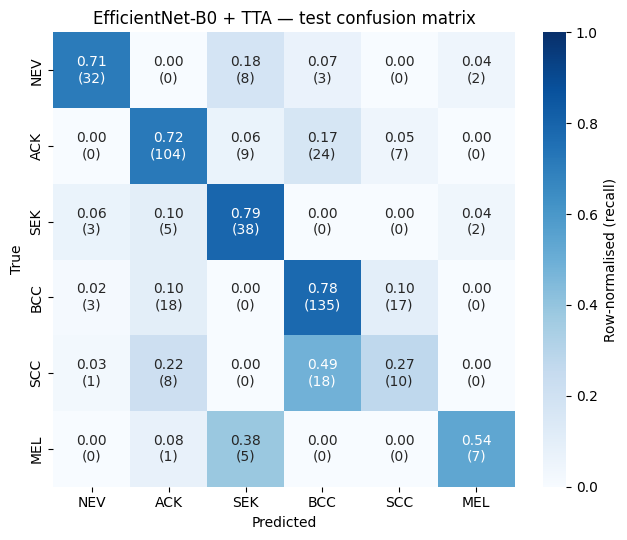

model,EfficientNet-B0 (no TTA),EfficientNet-B0 + TTA
accuracy,0.7043,0.7087
balanced_accuracy,0.6237,0.6357
macro_precision,0.6319,0.6498
macro_recall,0.6237,0.6357
macro_f1,0.6251,0.6397
weighted_f1,0.7045,0.7073
MEL_recall,0.5385,0.5385
binary_accuracy,0.8500,0.8500
binary_f1,0.8456,0.8456
binary_sensitivity,0.8475,0.8475


In [11]:
def evaluate(name, probs, y):
    pred = probs.argmax(1)
    p_cancer = probs[:, MAL_IDX].sum(1)
    y_bin, pred_bin = np.isin(y, MAL_IDX).astype(int), (p_cancer >= 0.5).astype(int)
    per_class_recall = recall_score(y, pred, average=None, labels=range(len(CLASSES)), zero_division=0)
    res = dict(model=name,
               accuracy=accuracy_score(y, pred),
               balanced_accuracy=balanced_accuracy_score(y, pred),
               macro_precision=precision_score(y, pred, average="macro", zero_division=0),
               macro_recall=recall_score(y, pred, average="macro", zero_division=0),
               macro_f1=f1_score(y, pred, average="macro", zero_division=0),
               weighted_f1=f1_score(y, pred, average="weighted", zero_division=0),
               MEL_recall=per_class_recall[LABEL_MAP["MEL"]],
               binary_accuracy=accuracy_score(y_bin, pred_bin),
               binary_f1=f1_score(y_bin, pred_bin),
               binary_sensitivity=recall_score(y_bin, pred_bin),
               binary_specificity=recall_score(y_bin, pred_bin, pos_label=0),
               binary_roc_auc=roc_auc_score(y_bin, p_cancer))
    print(f"\n===== {name} =====")
    print(classification_report(y, pred, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))
    return res, pred

def plot_cm(y, pred, title, fname):
    cm = confusion_matrix(y, pred, labels=range(len(CLASSES)))
    cm_norm = cm / cm.sum(1, keepdims=True)
    annot = np.array([[f"{cm_norm[i,j]:.2f}\n({cm[i,j]})" for j in range(len(CLASSES))] for i in range(len(CLASSES))])
    plt.figure(figsize=(6.5, 5.5))
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, cbar_kws={"label": "Row-normalised (recall)"})
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=200); plt.show()


test_dl = loader(test_df, eval_tf, False)
results = []
p_plain, y_test = predict(final_model, test_dl, tta=False)
res, _ = evaluate("EfficientNet-B0 (no TTA)", p_plain, y_test); results.append(res)
p_tta, _ = predict(final_model, test_dl, tta=True)
res, pred = evaluate("EfficientNet-B0 + TTA", p_tta, y_test); results.append(res)
plot_cm(y_test, pred, "EfficientNet-B0 + TTA — test confusion matrix", "cm_effnet_b0.png")
test_probs = p_tta if USE_TTA else p_plain

results_df = pd.DataFrame(results).set_index("model").round(4)
results_df.to_csv(OUT_DIR / "cnn_test_results_v3.csv")
results_df.T

## 9. All image models on the same test set

In [12]:
v1_results = pd.DataFrame([
    dict(model="SimpleCNN (v1)", accuracy=0.3348, balanced_accuracy=0.2971, macro_f1=0.2736, MEL_recall=0.2308,
         binary_accuracy=0.6913, binary_roc_auc=0.7441),
    dict(model="ResNet50 (v1)",  accuracy=0.6391, balanced_accuracy=0.5971, macro_f1=0.5837, MEL_recall=0.4615,
         binary_accuracy=0.8087, binary_roc_auc=0.9002),
]).set_index("model")
cols = ["accuracy", "balanced_accuracy", "macro_f1", "MEL_recall", "binary_accuracy", "binary_roc_auc"]
all_image = pd.concat([v1_results[cols], results_df[cols]])
all_image.to_csv(OUT_DIR / "all_image_models.csv")
print(f"5-fold CV (training set) macro-F1: {cv_df.macro_f1.mean():.3f} ± {cv_df.macro_f1.std():.3f}")
all_image

5-fold CV (training set) macro-F1: 0.659 ± 0.033


,accuracy,balanced_accuracy,macro_f1,MEL_recall,binary_accuracy,binary_roc_auc
model,,,,,,
SimpleCNN (v1),0.3348,0.2971,0.2736,0.2308,0.6913,0.7441
ResNet50 (v1),0.6391,0.5971,0.5837,0.4615,0.8087,0.9002
EfficientNet-B0 (no TTA),0.7043,0.6237,0.6251,0.5385,0.8500,0.9220
EfficientNet-B0 + TTA,0.7087,0.6357,0.6397,0.5385,0.8500,0.9224


## 10. Export for the fusion experiment
* `cnn_features_v3.csv.gz` — 1,280-d EfficientNet-B0 embedding from the final model, for every image.
* `cnn_probs_oof.csv` — 6 class probabilities per image: **out-of-fold** for training images (each predicted by the
  CV model that never saw it) and from the final model for test images. These are leak-free inputs for stacking /
  late fusion with the metadata models.
* `cnn_test_predictions_v3.csv` — per-image test predictions.

In [13]:
extractor = copy.deepcopy(final_model); extractor.classifier = nn.Identity(); extractor.eval()
feats = []
with torch.no_grad():
    for x, _ in DataLoader(LesionDS(df, eval_tf), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS):
        with torch.autocast(device.type, enabled=USE_AMP):
            feats.append(extractor(x.to(device)).float().cpu())
feats = torch.cat(feats).numpy()
feat_df = pd.concat([df[["img_id", "patient_id", "split", "fold", "diagnostic"]].reset_index(drop=True),
                     pd.DataFrame(feats.astype(np.float32), columns=[f"cnn_{i}" for i in range(feats.shape[1])])], axis=1)
feat_df.to_csv(OUT_DIR / "cnn_features_v3.csv.gz", index=False, float_format="%.5f")

prob_cols = [f"p_{c}" for c in CLASSES]
probs_df = df[["img_id", "patient_id", "split", "fold", "diagnostic"]].copy()
probs_df[prob_cols] = np.nan
probs_df.loc[oof.index, prob_cols] = oof.values
probs_df.loc[test_df.index, prob_cols] = test_probs
probs_df["source"] = np.where(probs_df.split == "test", "final_model", np.where(probs_df[prob_cols[0]].notna(), "out_of_fold", "no_oof_prediction"))
probs_df.to_csv(OUT_DIR / "cnn_probs_oof.csv", index=False)

pred_df = test_df[["img_id", "patient_id", "diagnostic"]].reset_index(drop=True)
pred_df = pd.concat([pred_df, pd.DataFrame(test_probs, columns=prob_cols)], axis=1)
pred_df["predicted"] = [CLASSES[i] for i in test_probs.argmax(1)]
pred_df.to_csv(OUT_DIR / "cnn_test_predictions_v3.csv", index=False)
print("features", feat_df.shape, "| probs", probs_df.source.value_counts().to_dict())
print("Saved to", OUT_DIR.resolve())

features (2298, 1285) | probs {'out_of_fold': 1825, 'final_model': 460, 'no_oof_prediction': 13}
Saved to /kaggle/working/cnn_outputs_v3
